In [24]:
import sys
import pandas as pd

print(sys.executable)
print(pd.__version__)

/opt/anaconda3/bin/python
2.2.3


# WM811K Wafer Map Exploration
Load and inspect the WM811K dataset before preprocessing and model training.

## 1. Load Dataset
Load the WM811K dataset from the pickle file into a pandas DataFrame.

In [25]:
df = pd.read_pickle("/Users/conniechen/Desktop/WM-811K wafer map/MIR-WM811K/Python/WM811K.pkl")

In [26]:
print(df.shape)
print(df.columns)
df.head()

(811457, 6)
Index(['dieSize', 'failureType', 'lotName', 'trainTestLabel', 'waferIndex',
       'waferMap'],
      dtype='object')


,dieSize,failureType,lotName,trainTestLabel,waferIndex,waferMap
0,1683.0,none,lot1,Training,1.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
1,1683.0,none,lot1,Training,2.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
2,1683.0,none,lot1,Training,3.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
3,1683.0,none,lot1,Training,4.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
4,1683.0,none,lot1,Training,5.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."


<class 'numpy.ndarray'>
(45, 48)


Text(0.5, 1.0, 'Wafer Map - Row 0')

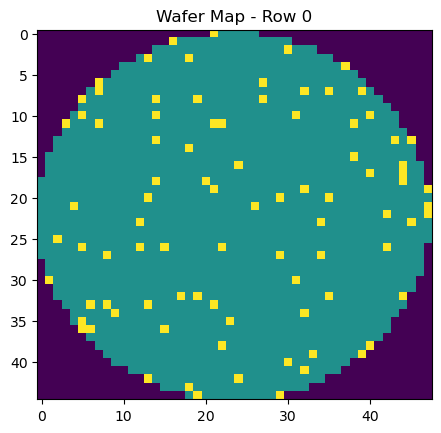

In [27]:
import matplotlib.pyplot as plt

wafer = df.iloc[0]["waferMap"]

print(type(wafer))
print(wafer.shape)

plt.imshow(wafer)
plt.title("Wafer Map - Row 0")
#plt.show()

In [28]:
import numpy as np

print(np.unique(wafer))

[0 1 2]


In [29]:
print("Lot:", df.iloc[0]["lotName"])
print("Wafer index:", df.iloc[0]["waferIndex"])
print("Failure type:", df.iloc[0]["failureType"])
print("Die size:", df.iloc[0]["dieSize"])

Lot: lot1
Wafer index: 1.0
Failure type: none
Die size: 1683.0


In [30]:
print(df.iloc[0]["failureType"])
print(type(df.iloc[0]["failureType"]))

none
<class 'str'>


In [31]:
print(df["failureType"].apply(type).value_counts())

failureType
<class 'numpy.ndarray'>    638507
<class 'str'>              172950
Name: count, dtype: int64


In [32]:
array_rows = df[df["failureType"].apply(lambda x: isinstance(x, np.ndarray))]

print(array_rows.iloc[0]["failureType"])
print(type(array_rows.iloc[0]["failureType"]))

[0 0]
<class 'numpy.ndarray'>


In [33]:
for i in range(20):
    print(array_rows.iloc[i]["failureType"])

[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]


In [34]:
def make_readable(x):
    if isinstance(x, np.ndarray):
        return str(x.tolist())
    return x

failure_readable = df["failureType"].apply(make_readable)

print(failure_readable.value_counts())

failureType
[0, 0]       638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [35]:
center_rows = df[failure_readable == "Center"]

print(center_rows.shape)

(4294, 6)


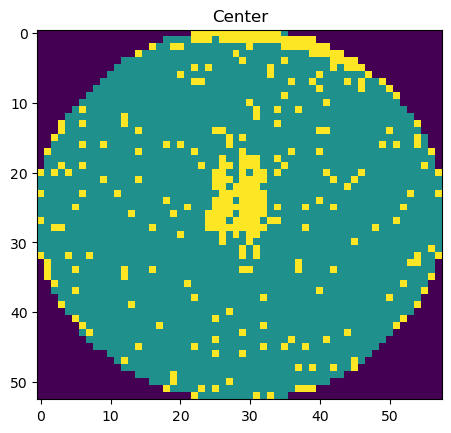

In [36]:
center_wafer = center_rows.iloc[0]["waferMap"]

plt.imshow(center_wafer)
plt.title("Center")
plt.show()

In [37]:
def show_example(label):
    rows = df[failure_readable == label]
    wafer = rows.iloc[0]["waferMap"]

    plt.imshow(wafer)
    plt.title(label)
    plt.show()

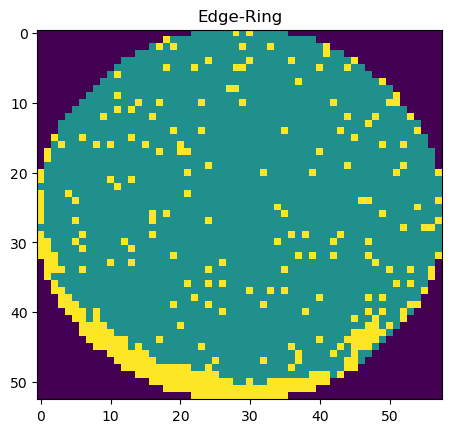

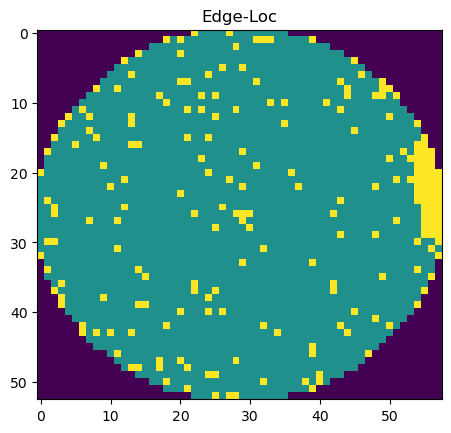

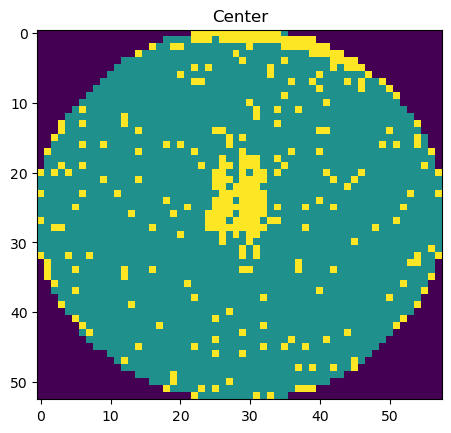

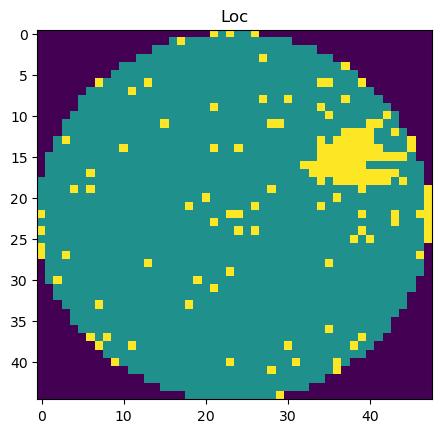

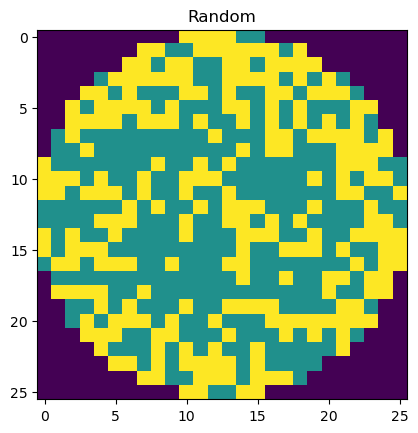

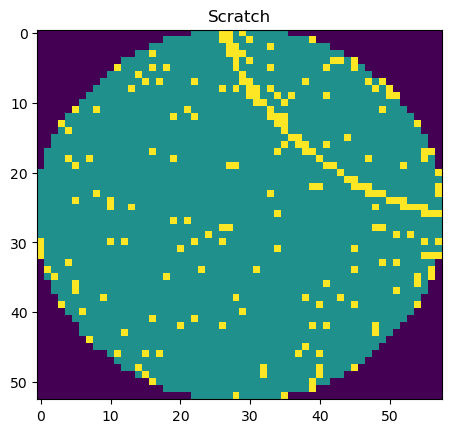

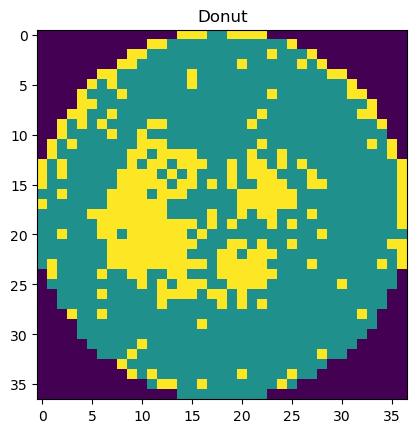

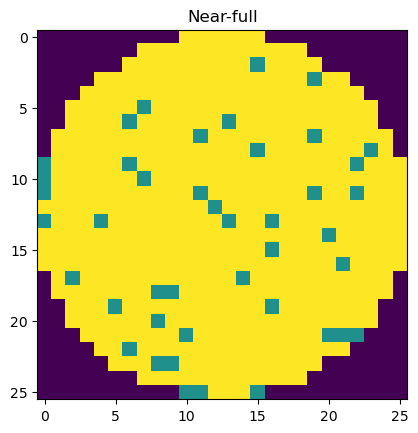

In [38]:
show_example("Edge-Ring")
show_example("Edge-Loc")
show_example("Center")
show_example("Loc")
show_example("Random")
show_example("Scratch")
show_example("Donut")
show_example("Near-full")


In [39]:
labeled_df = df[failure_readable != "[0, 0]"]

print(labeled_df.shape)

(172950, 6)


In [40]:
print(labeled_df.iloc[0]["waferMap"].shape)
print(labeled_df.iloc[1]["waferMap"].shape)
print(labeled_df.iloc[2]["waferMap"].shape)
print(labeled_df.iloc[100]["waferMap"].shape)
print(labeled_df.iloc[1000]["waferMap"].shape)

(45, 48)
(45, 48)
(45, 48)
(53, 58)
(26, 26)


In [41]:
wafer_shapes = labeled_df["waferMap"].apply(lambda x: x.shape)

print(wafer_shapes.value_counts().head(10))

waferMap
(25, 27)    18781
(26, 26)    14366
(30, 34)    12400
(29, 26)    11751
(27, 25)    10682
(39, 37)    10173
(33, 29)     8125
(42, 44)     6724
(44, 41)     6134
(41, 33)     5091
Name: count, dtype: int64


In [43]:
print("Number of different shapes:", wafer_shapes.nunique())

heights = wafer_shapes.apply(lambda x: x[0])
widths = wafer_shapes.apply(lambda x: x[1])

print("Height:", heights.min(), "to", heights.max())
print("Width:", widths.min(), "to", widths.max())

Number of different shapes: 346
Height: 15 to 212
Width: 3 to 204


## 3. Inspect Label Format
Check how the train/test labels and failure-type labels are stored in the original dataset.

In [44]:
print(type(df["trainTestLabel"].iloc[0]))
print(type(df["failureType"].iloc[0]))

print(df["trainTestLabel"].iloc[0])
print(df["failureType"].iloc[0])

<class 'str'>
<class 'str'>
Training
none


In [45]:
for i in [-2, -1]:
    for col in ["trainTestLabel", "failureType"]:
        value = df[col].iloc[i]
        print(i, col, type(value), repr(value))

-2 trainTestLabel <class 'numpy.ndarray'> array([0, 0], dtype=uint64)
-2 failureType <class 'numpy.ndarray'> array([0, 0], dtype=uint64)
-1 trainTestLabel <class 'numpy.ndarray'> array([0, 0], dtype=uint64)
-1 failureType <class 'numpy.ndarray'> array([0, 0], dtype=uint64)


## 4. Clean Label Columns
The original `trianTestLabel` and `failureType` values are stored as NumPy arrays, such as `[['Training']]` and `[['none']]`.

Extract the inner string values into new columns:
- `trianTestLabel` → `trainTestLabel_clean`
- `failureType` → `failureType_clean`

This makes the labels easier to analyze and use later for model training.

In [46]:
import numpy as np

def clean_label(x):
    if isinstance(x, str):
        return x

    if isinstance(x, np.ndarray) and x.size > 0:
        value = x.flatten()[0]
        if isinstance(value, str):
            return value

    return None

df["trainTestLabel_clean"] = df["trainTestLabel"].apply(clean_label)
df["failureType_clean"] = df["failureType"].apply(clean_label)

In [47]:
print(df["trainTestLabel_clean"].value_counts(dropna=False))
print(df["failureType_clean"].value_counts(dropna=False))

trainTestLabel_clean
None        638507
Test        118595
Training     54355
Name: count, dtype: int64
failureType_clean
None         638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [48]:
df['failureType_clean'].dtypes

dtype('O')

In [49]:
df = df.dropna(subset=['failureType_clean'])
df = df[df["failureType_clean"] != "None"]
print(df)

        dieSize failureType   lotName trainTestLabel  waferIndex  \
0        1683.0        none      lot1       Training         1.0   
1        1683.0        none      lot1       Training         2.0   
2        1683.0        none      lot1       Training         3.0   
3        1683.0        none      lot1       Training         4.0   
4        1683.0        none      lot1       Training         5.0   
...         ...         ...       ...            ...         ...   
811450    600.0    Edge-Loc  lot47542           Test        21.0   
811451    600.0    Edge-Loc  lot47542           Test        22.0   
811452    600.0   Edge-Ring  lot47542           Test        23.0   
811453    600.0    Edge-Loc  lot47542           Test        24.0   
811454    600.0   Edge-Ring  lot47542           Test        25.0   

                                                 waferMap  \
0       [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   
1       [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   


In [50]:
print(df["failureType_clean"].value_counts(dropna=False))

failureType_clean
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [51]:
print("Total wafers:", len(df))
print("Total lots:", df["lotName"].nunique())
print("Missing lotName:", df["lotName"].isna().sum())

print("\nWafers per lot:")
print(df["lotName"].value_counts().describe())

Total wafers: 172950
Total lots: 10762
Missing lotName: 0

Wafers per lot:
count    10762.000000
mean        16.070433
std         10.579723
min          1.000000
25%          2.000000
50%         23.000000
75%         25.000000
max         25.000000
Name: count, dtype: float64


how many class are there in each lot

In [52]:
lot_class_counts = pd.crosstab(
    df["lotName"],
    df["failureType_clean"]
)

print(lot_class_counts)

failureType_clean  Center  Donut  Edge-Loc  Edge-Ring  Loc  Near-full  Random  \
lotName                                                                         
lot1                    0      0         0          0    1          0       0   
lot10                   0      0         0          0    0          0       0   
lot100                  0      0         0          0    0          0       0   
lot10006                1      0         0          0    0          0       0   
lot10008                0      0         0         24    0          0       0   
...                   ...    ...       ...        ...  ...        ...     ...   
lot9979                 1      0         0          0    0          0       0   
lot9983                 1      0         0          0    0          0       0   
lot9992                 0      0         5          0    0          0       0   
lot9995                 3      0         1          0    0          0       0   
lot9997                 5   

In [53]:
near_full_lots = lot_class_counts[
    lot_class_counts["Near-full"] > 0
]

print("Lots containing Near-full:", len(near_full_lots))
print(near_full_lots["Near-full"].describe())

Lots containing Near-full: 137
count    137.000000
mean       1.087591
std        0.392474
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        4.000000
Name: Near-full, dtype: float64


In [54]:
for class_name in lot_class_counts.columns:
    num_lots = (lot_class_counts[class_name] > 0).sum()
    num_wafers = lot_class_counts[class_name].sum()

    print(
        class_name,
        "- wafers:", num_wafers,
        "- lots:", num_lots
    )

Center - wafers: 4294 - lots: 1648
Donut - wafers: 555 - lots: 233
Edge-Loc - wafers: 5189 - lots: 3211
Edge-Ring - wafers: 9680 - lots: 1075
Loc - wafers: 3593 - lots: 2472
Near-full - wafers: 149 - lots: 137
Random - wafers: 866 - lots: 449
Scratch - wafers: 1193 - lots: 1059
none - wafers: 147431 - lots: 6591


In [55]:
all_lots = df["lotName"].unique()

print(len(all_lots))
print(all_lots[:10])

10762
['lot1' 'lot2' 'lot3' 'lot4' 'lot5' 'lot6' 'lot7' 'lot8' 'lot9' 'lot10']


In [56]:
from sklearn.model_selection import train_test_split

train_lots, temp_lots = train_test_split(
    all_lots,
    test_size=0.2,
    random_state=42
)

print("Train lots:", len(train_lots))
print("Temporary lots:", len(temp_lots))

Train lots: 8609
Temporary lots: 2153


In [57]:
val_lots, test_lots = train_test_split(
    temp_lots,
    test_size=0.5,
    random_state=42
)

print("Validation lots:", len(val_lots))
print("Test lots:", len(test_lots))

Validation lots: 1076
Test lots: 1077


In [58]:
train_df = df[df["lotName"].isin(train_lots)].copy()
val_df = df[df["lotName"].isin(val_lots)].copy()
test_df = df[df["lotName"].isin(test_lots)].copy()

print("Train wafers:", len(train_df))
print("Validation wafers:", len(val_df))
print("Test wafers:", len(test_df))

Train wafers: 138987
Validation wafers: 17249
Test wafers: 16714


In [59]:
print("Train & Val overlap:",
      len(set(train_lots) & set(val_lots)))

print("Train & Test overlap:",
      len(set(train_lots) & set(test_lots)))

print("Val & Test overlap:",
      len(set(val_lots) & set(test_lots)))

Train & Val overlap: 0
Train & Test overlap: 0
Val & Test overlap: 0


In [60]:
print("TRAIN")
print(train_df["failureType_clean"].value_counts())

print("\nVALIDATION")
print(val_df["failureType_clean"].value_counts())

print("\nTEST")
print(test_df["failureType_clean"].value_counts())

TRAIN
failureType_clean
none         118583
Edge-Ring      7728
Edge-Loc       4111
Center         3467
Loc            2896
Scratch         966
Random          703
Donut           425
Near-full       108
Name: count, dtype: int64

VALIDATION
failureType_clean
none         14549
Edge-Ring     1101
Edge-Loc       533
Center         466
Loc            339
Scratch        116
Donut           63
Random          54
Near-full       28
Name: count, dtype: int64

TEST
failureType_clean
none         14299
Edge-Ring      851
Edge-Loc       545
Center         361
Loc            358
Scratch        111
Random         109
Donut           67
Near-full       13
Name: count, dtype: int64


deal with class imblance 

Train:

none       118,583
Near-full      108

experiment A BALANCE baseline 108 

In [62]:
train_df["failureType_clean"].unique()

array(['none', 'Edge-Loc', 'Loc', 'Center', 'Edge-Ring', 'Scratch',
       'Random', 'Near-full', 'Donut'], dtype=object)

In [64]:
samples_per_class = 108

balanced_train_df = (
    train_df
    .groupby("failureType_clean")
    .sample(
        n=samples_per_class,
        random_state=42
    )
    .reset_index(drop=True)
)

In [65]:
train_df.groupby("failureType_clean")

In [67]:
print(balanced_train_df.shape)

print(
    balanced_train_df["failureType_clean"].value_counts()
) 

(972, 8)
failureType_clean
Center       108
Donut        108
Edge-Loc     108
Edge-Ring    108
Loc          108
Near-full    108
Random       108
Scratch      108
none         108
Name: count, dtype: int64
